# N-Queens SAT Encodings Benchmark Visualization

Notebook trực quan hóa hiệu năng của 5 phương pháp mã hóa CNF cho bài toán N-Queens:
- **Binomial Encoding** (Direct pairwise encoding)
- **Binary Encoding** (Logarithmic bit encoding)
- **Sequential Counter Encoding** (Sequential accumulation registers)
- **Commander Encoding** (Group partition with commander variables)
- **Product Encoding** (2D grid product coordinates)

Dữ liệu được nạp trực tiếp từ `encoding_results.csv` với 17 kích thước bàn cờ ($4 \times 4$ đến $1000 \times 1000$). Toàn bộ các biểu đồ đều sử dụng **thang đo tuyến tính (Linear Scale)**.

In [2]:
import csv
import matplotlib.pyplot as plt

%matplotlib inline

CSV_FILE = "encoding_results.csv"

# Danh sách 17 kích thước chuẩn
N_LIST = [4, 8, 9, 16, 25, 27, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
LABELS = [f"{n}x{n}" for n in N_LIST]
X_INDICES = list(range(len(N_LIST)))

# Định nghĩa bảng màu và marker học thuật riêng biệt cho từng Encoding
ENCODING_STYLES = {
    "Binomial": {"color": "#1E40AF", "marker": "o"},          # Deep Blue
    "Binary": {"color": "#059669", "marker": "s"},            # Emerald Green
    "Sequential Counter": {"color": "#D97706", "marker": "^"},# Amber
    "Commander": {"color": "#7C3AED", "marker": "D"},         # Purple/Violet
    "Product": {"color": "#DC2626", "marker": "v"}            # Crimson Red
}

name_map = {
    "Binomial": "Binomial",
    "Binary": "Binary",
    "Sequential": "Sequential Counter",
    "Commander": "Commander",
    "Product": "Product"
}

plot_data = {name: {"x_c": [], "clauses": [], "x_v": [], "vars": [], "x_t": [], "time": []} for name in ENCODING_STYLES}

with open(CSV_FILE, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        if not row.get("N") or not row["N"].strip():
            continue
        n = int(row["N"])
        if n not in N_LIST:
            continue
        idx = N_LIST.index(n)
        raw_enc = row.get("Encoding")
        if raw_enc is None:
            continue
        enc = name_map.get(raw_enc)
        if not enc:
            continue
        
        # Clauses
        if row.get("Clauses") and row["Clauses"] not in ("-", "OOM", ""):
            plot_data[enc]["x_c"].append(idx)
            plot_data[enc]["clauses"].append(int(row["Clauses"]))
        
        # Variables
        if row.get("Variables") and row["Variables"] not in ("-", "OOM", ""):
            plot_data[enc]["x_v"].append(idx)
            plot_data[enc]["vars"].append(int(row["Variables"]))
        
        # Time
        if row.get("Status") == "SAT" and row.get("Time_Seconds") and row["Time_Seconds"] not in ("timeout", "-", ""):
            plot_data[enc]["x_t"].append(idx)
            plot_data[enc]["time"].append(float(row["Time_Seconds"]))

print("[OK] Nạp dữ liệu thành công từ encoding_results.csv!")

[OK] Nạp dữ liệu thành công từ encoding_results.csv!


## 1. Biểu đồ so sánh số lượng mệnh đề (CNF Clauses)

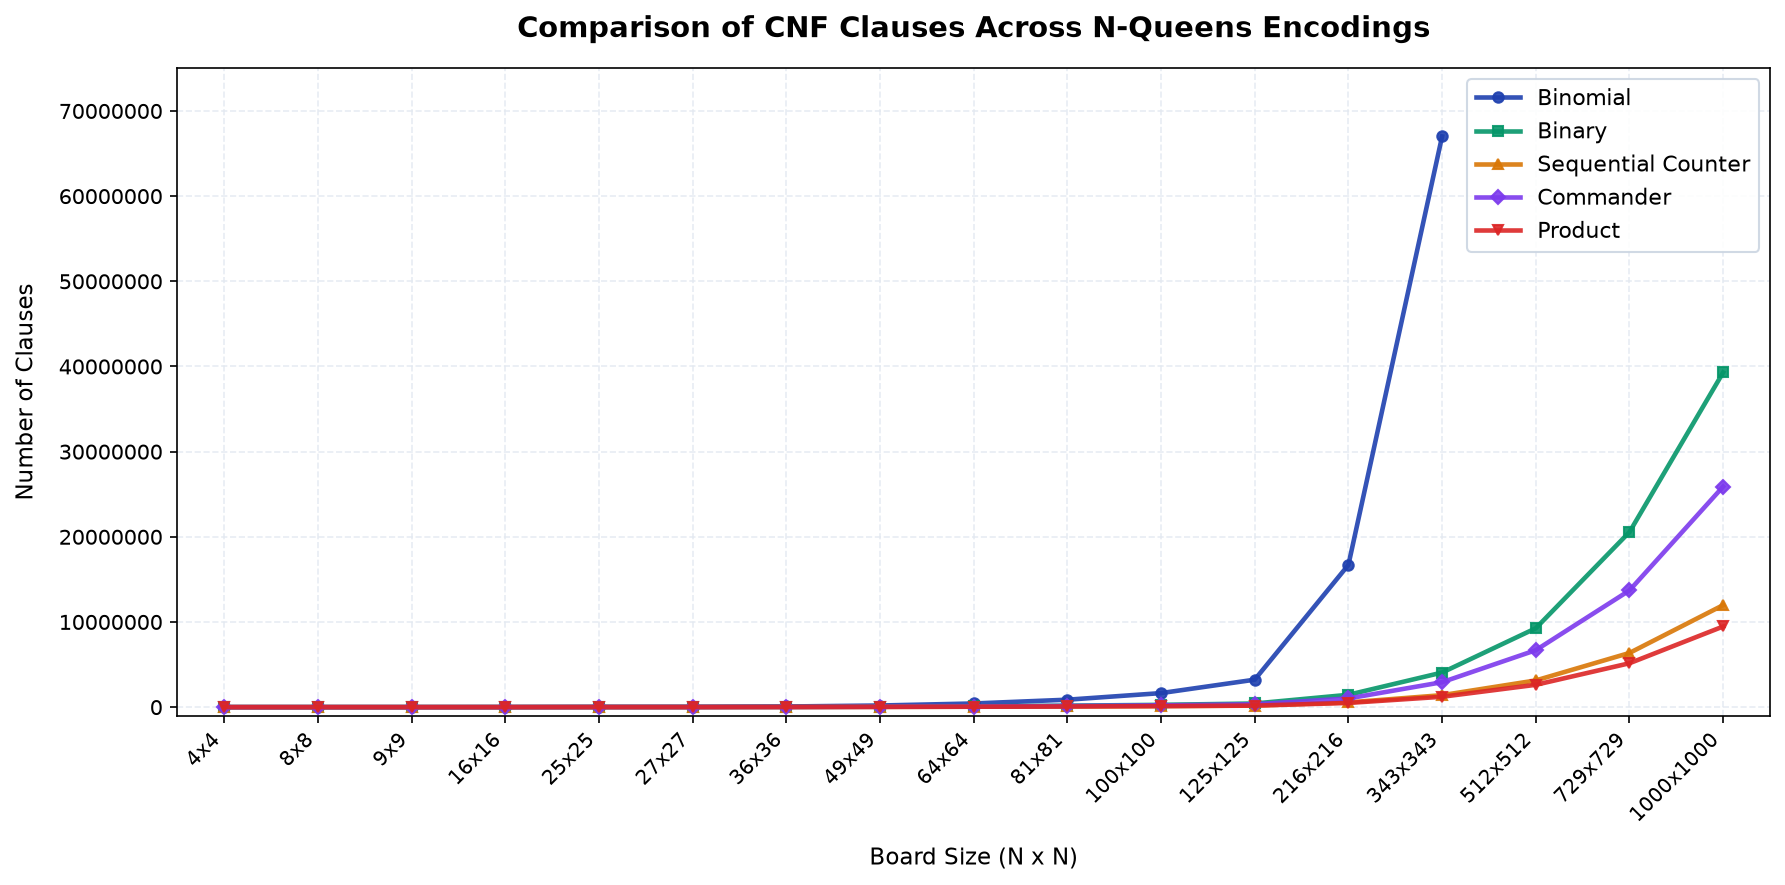

In [2]:
plt.figure(figsize=(12, 6), dpi=150)
for name, style in ENCODING_STYLES.items():
    plt.plot(plot_data[name]["x_c"], plot_data[name]["clauses"], 
             label=name, color=style["color"], marker=style["marker"], 
             markersize=5, linewidth=2.2, alpha=0.9)

plt.title("Comparison of CNF Clauses Across N-Queens Encodings", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Board Size (N x N)", fontsize=11, labelpad=10)
plt.ylabel("Number of Clauses", fontsize=11, labelpad=10)
plt.xticks(X_INDICES, LABELS, rotation=45, ha="right", fontsize=9.5)
plt.xlim(-0.5, len(N_LIST) - 0.5)
plt.ylim(-1_000_000, 75_000_000)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, linestyle="--", color="#E2E8F0", alpha=0.8)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="#CBD5E1", fontsize=10.5)
plt.tight_layout()
plt.show()

## 2. Biểu đồ so sánh số lượng biến (Boolean Variables)

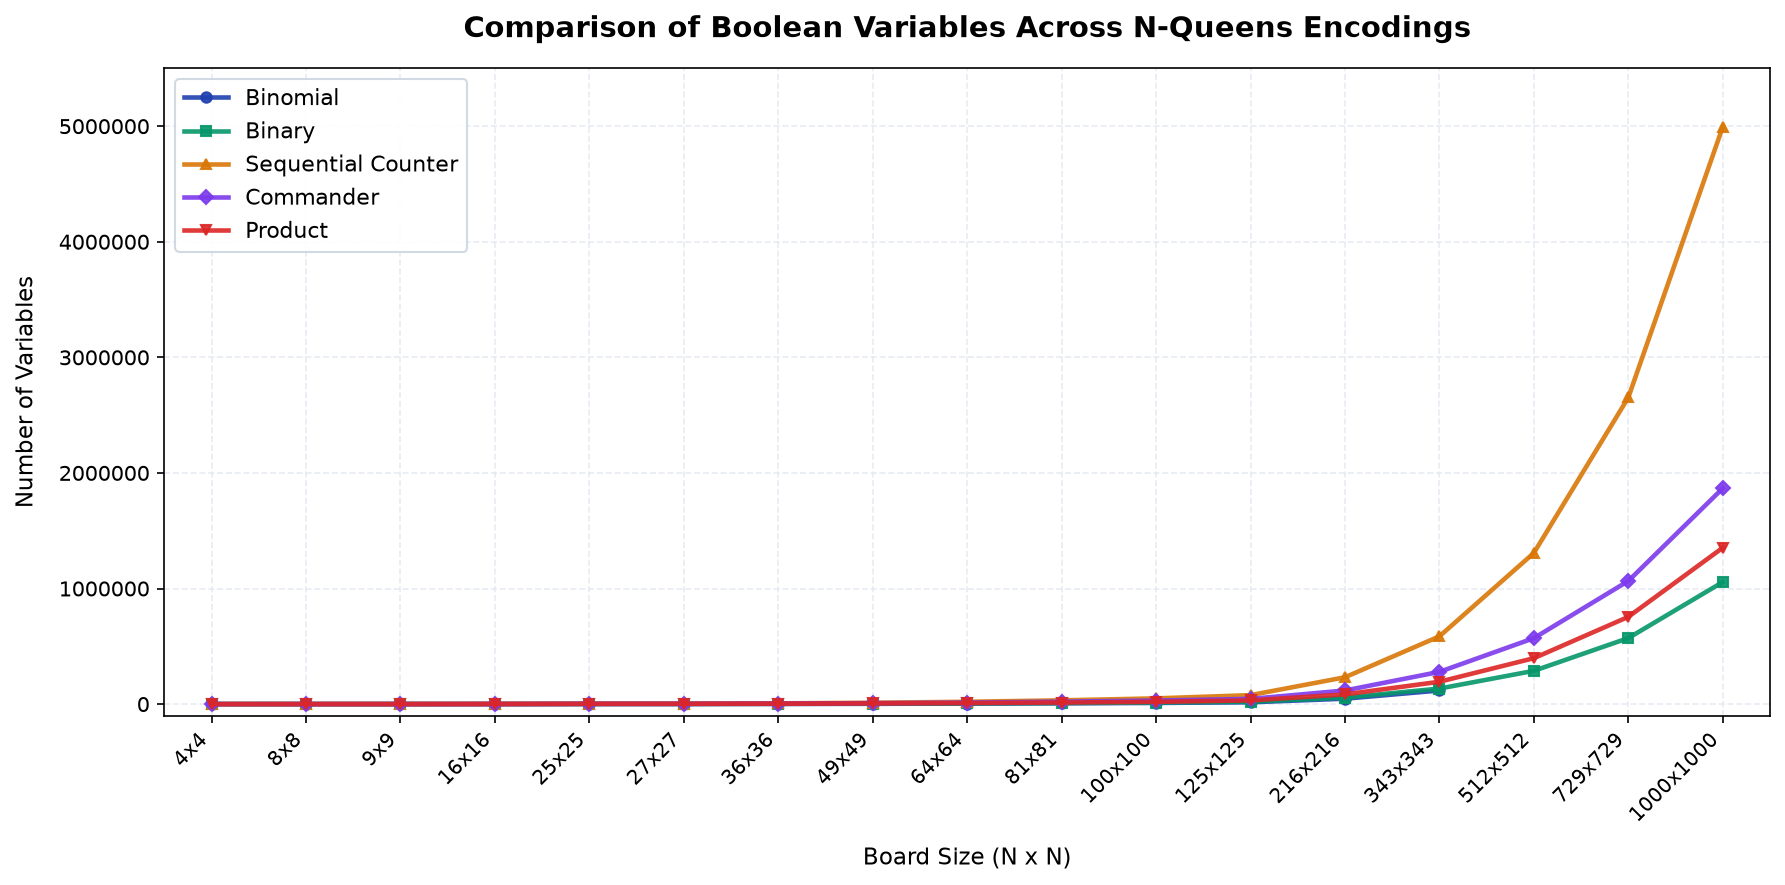

In [3]:
plt.figure(figsize=(12, 6), dpi=150)
for name, style in ENCODING_STYLES.items():
    plt.plot(plot_data[name]["x_v"], plot_data[name]["vars"], 
             label=name, color=style["color"], marker=style["marker"], 
             markersize=5, linewidth=2.2, alpha=0.9)

plt.title("Comparison of Boolean Variables Across N-Queens Encodings", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Board Size (N x N)", fontsize=11, labelpad=10)
plt.ylabel("Number of Variables", fontsize=11, labelpad=10)
plt.xticks(X_INDICES, LABELS, rotation=45, ha="right", fontsize=9.5)
plt.xlim(-0.5, len(N_LIST) - 0.5)
plt.ylim(-100_000, 5_500_000)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, linestyle="--", color="#E2E8F0", alpha=0.8)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="#CBD5E1", fontsize=10.5)
plt.tight_layout()
plt.show()

## 3. Biểu đồ so sánh thời gian thực thi (Execution Time)

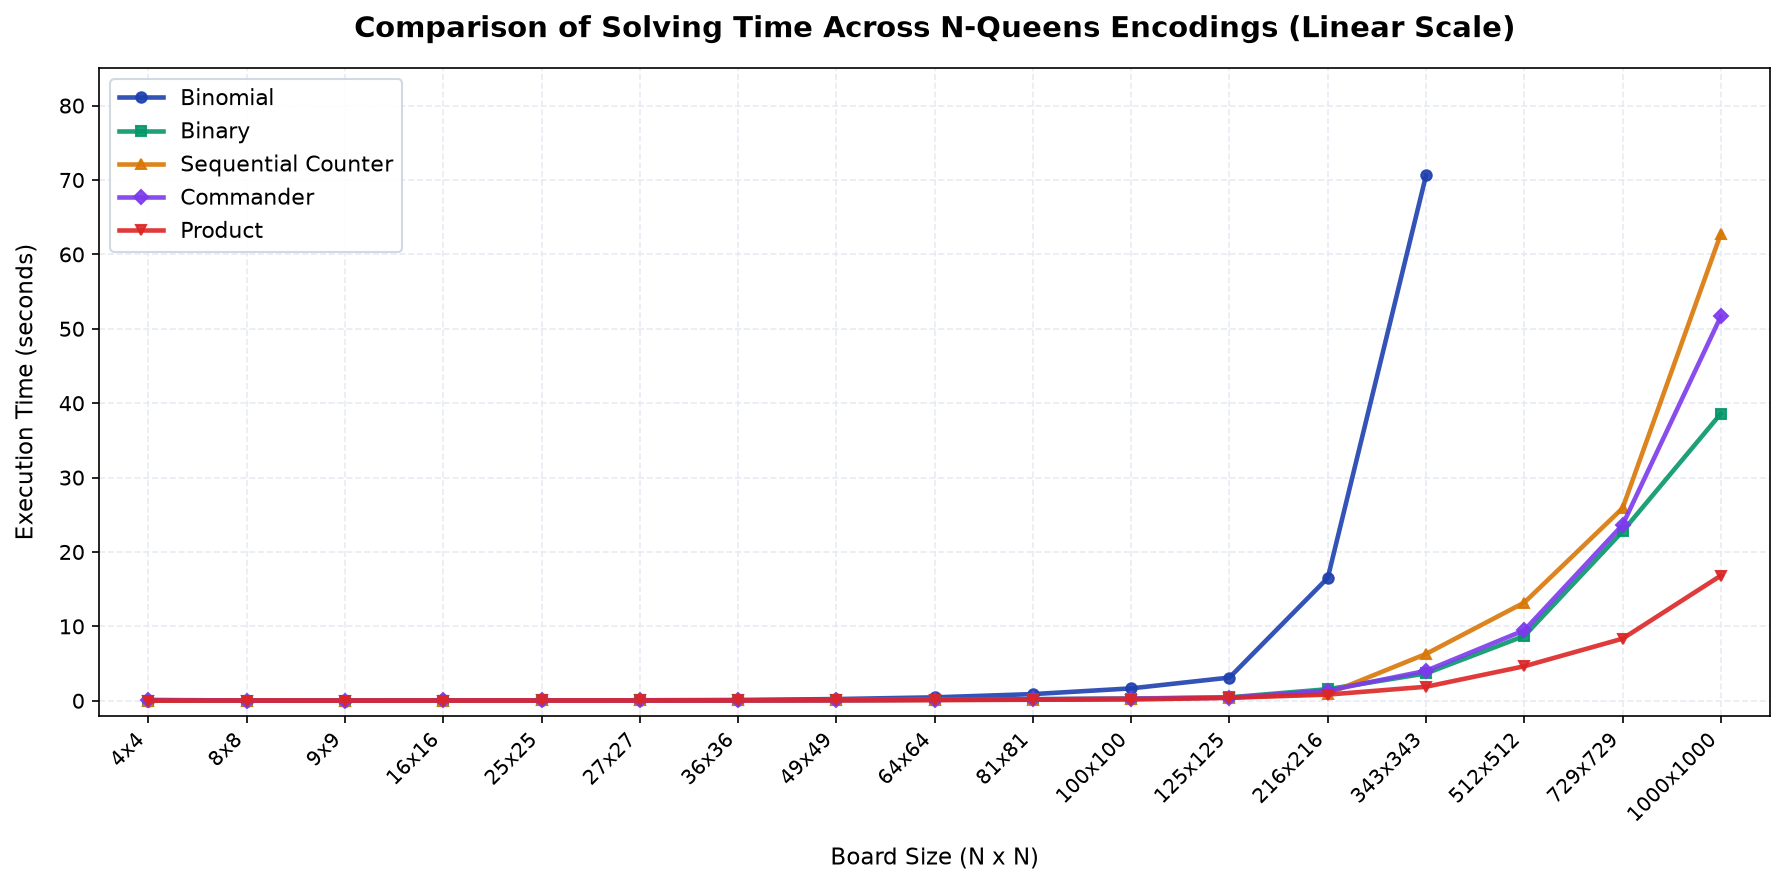

In [4]:
plt.figure(figsize=(12, 6), dpi=150)
for name, style in ENCODING_STYLES.items():
    plt.plot(plot_data[name]["x_t"], plot_data[name]["time"], 
             label=name, color=style["color"], marker=style["marker"], 
             markersize=5, linewidth=2.2, alpha=0.9)

plt.title("Comparison of Solving Time Across N-Queens Encodings (Linear Scale)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Board Size (N x N)", fontsize=11, labelpad=10)
plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=10)
plt.xticks(X_INDICES, LABELS, rotation=45, ha="right", fontsize=9.5)
plt.xlim(-0.5, len(N_LIST) - 0.5)
plt.ylim(-2, 85)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, linestyle="--", color="#E2E8F0", alpha=0.8)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, edgecolor="#CBD5E1", fontsize=10.5)
plt.tight_layout()
plt.show()